# 00 – Exploratory Data Analysis and Evaluation Metric

## 1. Setup
Import libraries. Everything here is pre-installed on Google Colab.

In [1]:
# Core libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# scikit-learn: pre-processing, models, validation
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, RandomizedSearchCV,
                                     cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.base import clone

In [3]:
# Models and metrics
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import calibration_curve
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, log_loss, confusion_matrix
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_classif

In [4]:
# Global settings
RANDOM_STATE = 42          # fixed seed so results are reproducible
TARGET = 'seasonal_vaccine'
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 50)

## 2. Load the data

In [5]:
TRAIN_PATH = 'dataset_A_training.csv'
TEST_PATH = 'dataset_A_testing.csv'

# In Colab, upload the files if they are not already present
if not (os.path.exists(TRAIN_PATH) and os.path.exists(TEST_PATH)):
    from google.colab import files
    files.upload()   # choose both CSV files

In [6]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
print('Train shape:', train.shape)
print('Test shape :', test.shape)

Train shape: (4756, 31)
Test shape : (4749, 30)


In [7]:
train.head()

,respondent_id,flu_concern,flu_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,doctor_recc_seasonal,child_under_6_months,health_worker,health_insurance,opinion_seas_vacc_effective,opinion_seas_risk,opinion_seas_sick_from_vacc,age_group,education,race,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,seasonal_vaccine
0,1,2.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,4.0,2.0,18 - 34 Years,12 Years,White,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,0.0,0.0,entertainment,0,0
1,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,4.0,4.0,18 - 34 Years,Some College,White,Male,NaN,Not Married,Rent,Employed,"MSA, Principle City",1.0,0.0,education,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,4.0,2.0,1.0,65+ Years,College Graduate,White,Male,"> $75,000",Married,Own,Not in Labor Force,"MSA, Not Principle City",1.0,0.0,NaN,0,0
3,4,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,NaN,0.0,0.0,1.0,3.0,3.0,1.0,55 - 64 Years,College Graduate,White,Male,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",1.0,2.0,utilities,0,1
4,5,2.0,2.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,NaN,3.0,1.0,1.0,55 - 64 Years,12 Years,White,Female,Below Poverty,Not Married,Rent,Not in Labor Force,"MSA, Not Principle City",2.0,0.0,NaN,1,0


## 3. Exploratory data analysis
### 3.1 Structure and feature groups
Using the dataset information sheet, we group the features by type. The groups decide how each feature is pre-processed later.

In [8]:
# Binary (0/1) features
BINARY = ['behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
          'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home',
          'behavioral_touch_face', 'doctor_recc_seasonal', 'child_under_6_months',
          'health_worker', 'health_insurance']

# Numeric ordinal scales and counts
ORDINAL_NUM = ['flu_concern', 'flu_knowledge', 'opinion_seas_vacc_effective',
               'opinion_seas_risk', 'opinion_seas_sick_from_vacc',
               'household_adults', 'household_children', 'number_chronic_med_conditions']

In [9]:
# Text categories that have a natural order (encoded as ranks in option B)
ORDERED_CAT = {
    'age_group': ['18 - 34 Years', '35 - 44 Years', '45 - 54 Years', '55 - 64 Years', '65+ Years'],
    'education': ['< 12 Years', '12 Years', 'Some College', 'College Graduate'],
    'income_poverty': ['Below Poverty', '<= $75,000, Above Poverty', '> $75,000'],
}

# Text categories with no order (one-hot encoded)
NOMINAL = ['race', 'sex', 'marital_status', 'rent_or_own', 'employment_status',
           'census_msa', 'employment_sector']

FEATURES = BINARY + ORDINAL_NUM + list(ORDERED_CAT) + NOMINAL
print(len(FEATURES), 'features')

29 features


In [10]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   flu_concern                    4744 non-null   float64
 2   flu_knowledge                  4733 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4724 non-null   float64
 5   behavioral_face_mask           4753 non-null   float64
 6   behavioral_wash_hands          4748 non-null   float64
 7   behavioral_large_gatherings    4747 non-null   float64
 8   behavioral_outside_home        4747 non-null   float64
 9   behavioral_touch_face          4737 non-null   float64
 10  doctor_recc_seasonal           4435 non-null   float64
 11  child_under_6_months           4604 non-null   float64
 12  health_worker                  4607 non-null   float64
 13 

In [11]:
train[BINARY + ORDINAL_NUM].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
behavioral_antiviral_meds,4742.0,0.05,0.22,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4724.0,0.73,0.44,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4753.0,0.07,0.26,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4748.0,0.84,0.37,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4747.0,0.37,0.48,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4747.0,0.34,0.47,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4737.0,0.69,0.46,0.0,0.0,1.0,1.0,1.0
doctor_recc_seasonal,4435.0,0.37,0.48,0.0,0.0,0.0,1.0,1.0
child_under_6_months,4604.0,0.09,0.29,0.0,0.0,0.0,0.0,1.0
health_worker,4607.0,0.14,0.34,0.0,0.0,0.0,0.0,1.0


In [12]:
# Data quality checks: duplicated rows and unique IDs
print('Duplicated rows (ignoring id):', train.duplicated(subset=FEATURES + [TARGET]).sum())
print('Unique train IDs:', train['respondent_id'].is_unique)
print('Train/test ID overlap:', len(set(train.respondent_id) & set(test.respondent_id)))

Duplicated rows (ignoring id): 0
Unique train IDs: True
Train/test ID overlap: 0


### 3.2 Target distribution

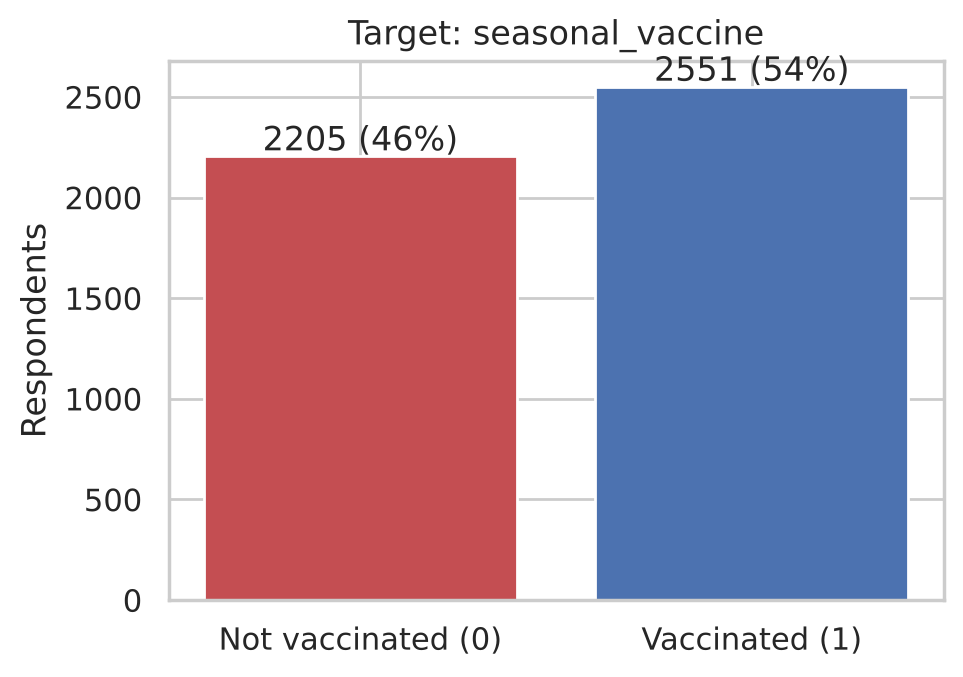

In [13]:
fig, ax = plt.subplots(figsize=(5, 3.5))
counts = train[TARGET].value_counts().sort_index()
ax.bar(['Not vaccinated (0)', 'Vaccinated (1)'], counts.values, color=['#c44e52', '#4c72b0'])
for i, v in enumerate(counts.values):
    ax.text(i, v + 30, f'{v} ({v / len(train):.0%})', ha='center')
ax.set_title('Target: seasonal_vaccine'); ax.set_ylabel('Respondents')
plt.show()

The classes are roughly balanced, so no resampling is needed. The **cost** of each error type matters far more than class balance (Section 4).

### 3.3 Missing values

In [14]:
# Percentage of missing values per column, train vs test
miss = pd.DataFrame({'train': train[FEATURES].isna().mean() * 100,
                     'test': test[FEATURES].isna().mean() * 100})
miss = miss[miss.train > 0].sort_values('train', ascending=False)
miss.round(1)

,train,test
employment_sector,48.7,50.6
health_insurance,40.5,41.7
income_poverty,16.6,16.8
rent_or_own,8.0,8.0
doctor_recc_seasonal,6.7,7.3
education,5.7,5.7
employment_status,5.7,5.8
marital_status,5.6,5.7
child_under_6_months,3.2,3.3
health_worker,3.1,3.1


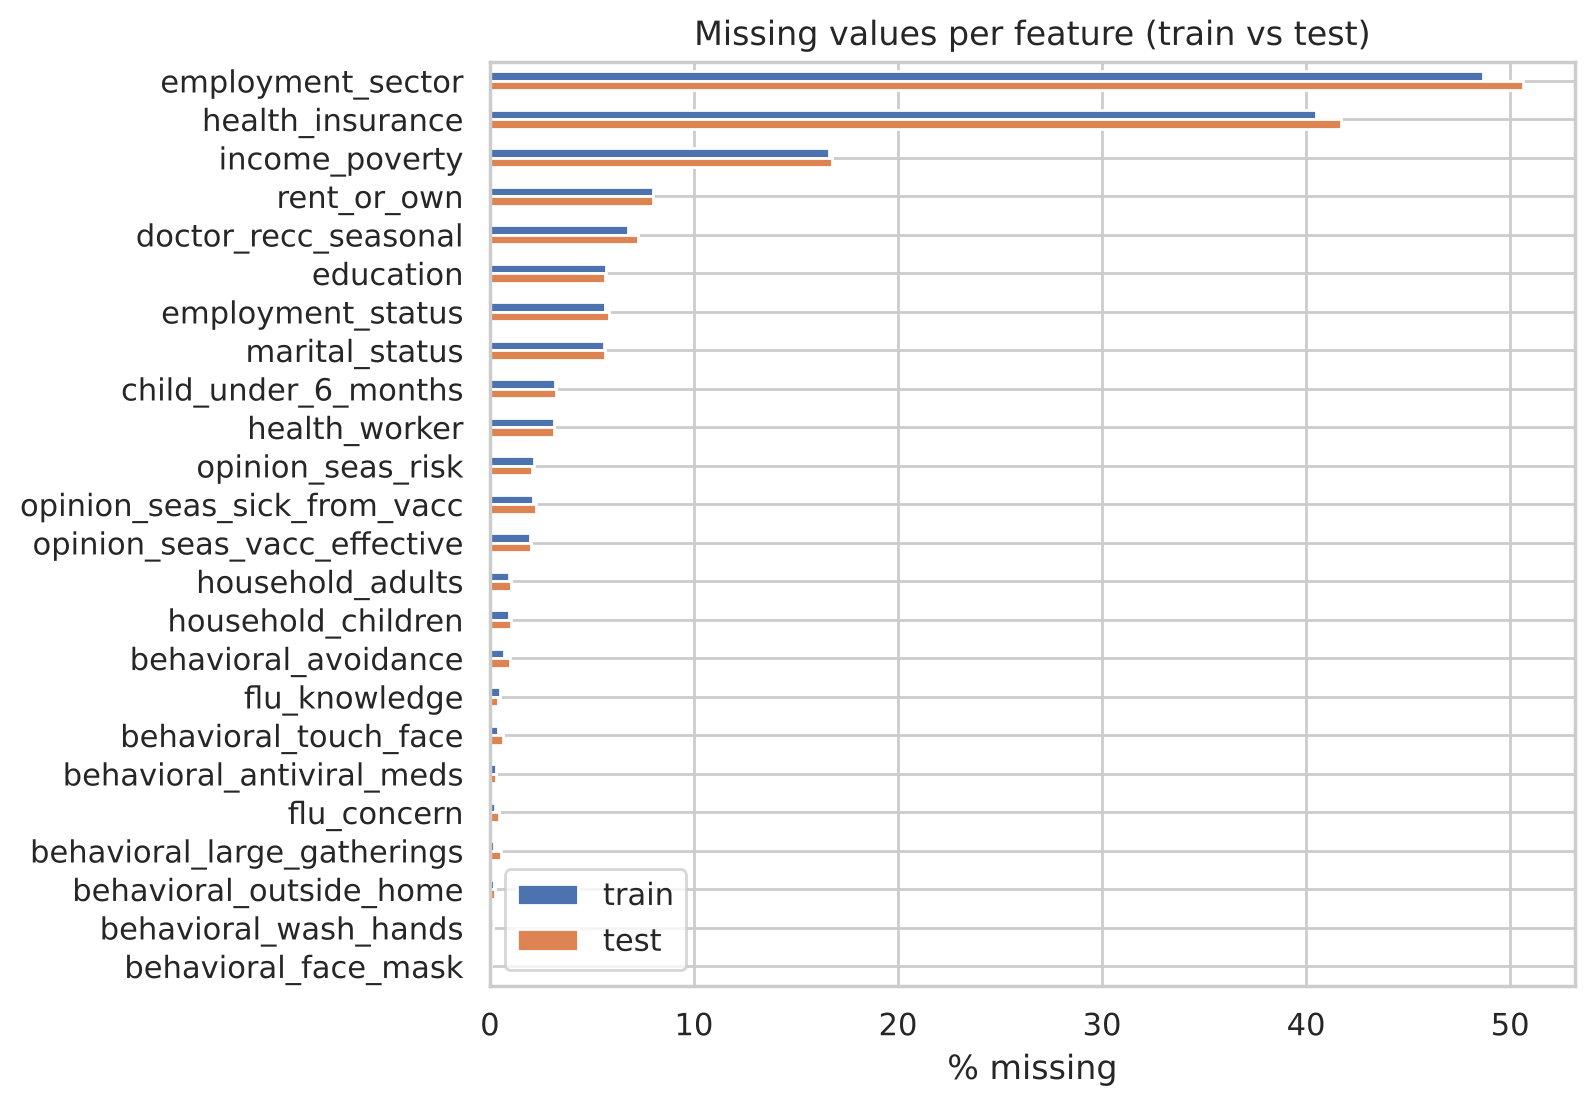

In [15]:
ax = miss.plot.barh(figsize=(7, 6), color=['#4c72b0', '#dd8452'])
ax.invert_yaxis(); ax.set_xlabel('% missing')
ax.set_title('Missing values per feature (train vs test)')
plt.show()

Is missingness itself informative? We compare the vaccination rate of respondents with and without a missing value.

In [16]:
# Vaccination rate when the value is missing vs present
rows = []
for col in miss.index:
    is_na = train[col].isna()
    rows.append({'feature': col,
                 'rate_if_missing': train.loc[is_na, TARGET].mean(),
                 'rate_if_present': train.loc[~is_na, TARGET].mean()})
miss_effect = pd.DataFrame(rows).set_index('feature').round(3)
miss_effect.head(8)

,rate_if_missing,rate_if_present
feature,,
employment_sector,0.568,0.506
health_insurance,0.462,0.587
income_poverty,0.513,0.541
rent_or_own,0.459,0.543
doctor_recc_seasonal,0.393,0.547
education,0.415,0.544
employment_status,0.416,0.544
marital_status,0.411,0.544


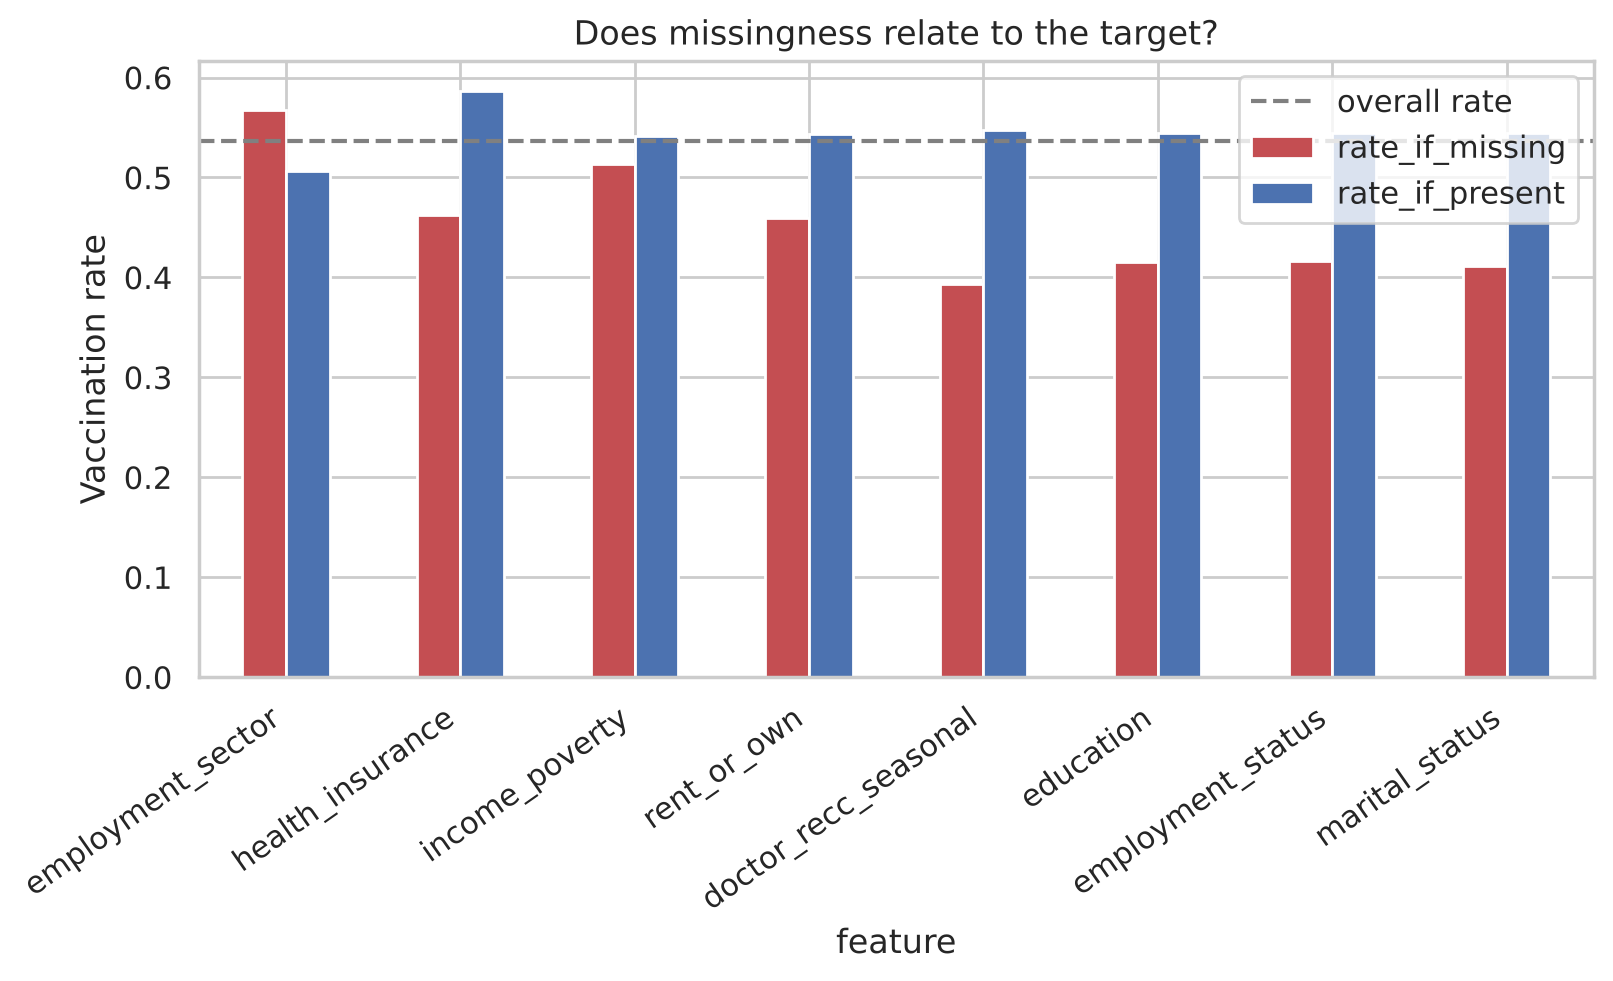

In [17]:
ax = miss_effect.head(8).plot.bar(figsize=(9, 4), color=['#c44e52', '#4c72b0'])
ax.axhline(train[TARGET].mean(), ls='--', c='grey', label='overall rate')
ax.set_ylabel('Vaccination rate'); ax.set_title('Does missingness relate to the target?')
ax.legend(); plt.xticks(rotation=35, ha='right'); plt.show()

In [18]:
# employment_sector is missing almost exactly when the person is not employed
pd.crosstab(train['employment_status'].fillna('Missing'),
            train['employment_sector'].isna().rename('sector_missing'))

sector_missing,False,True
employment_status,,
Employed,2442,25
Missing,0,269
Not in Labor Force,0,1786
Unemployed,0,234


**Findings on missing data**
- `employment_sector` (~49% missing) is **structurally missing**: it is blank for almost everyone who is not employed.
  Imputing the most frequent sector would be wrong, so we either drop it or give it its own category.
- `health_insurance` (~41% missing) is missing in a way that **relates to the target** (lower vaccination rate when missing),
  so a missing-value indicator should carry useful signal.
- Train and test have very similar missingness, so the same pre-processing will transfer to the test set.

### 3.4 Distributions of binary and ordinal features

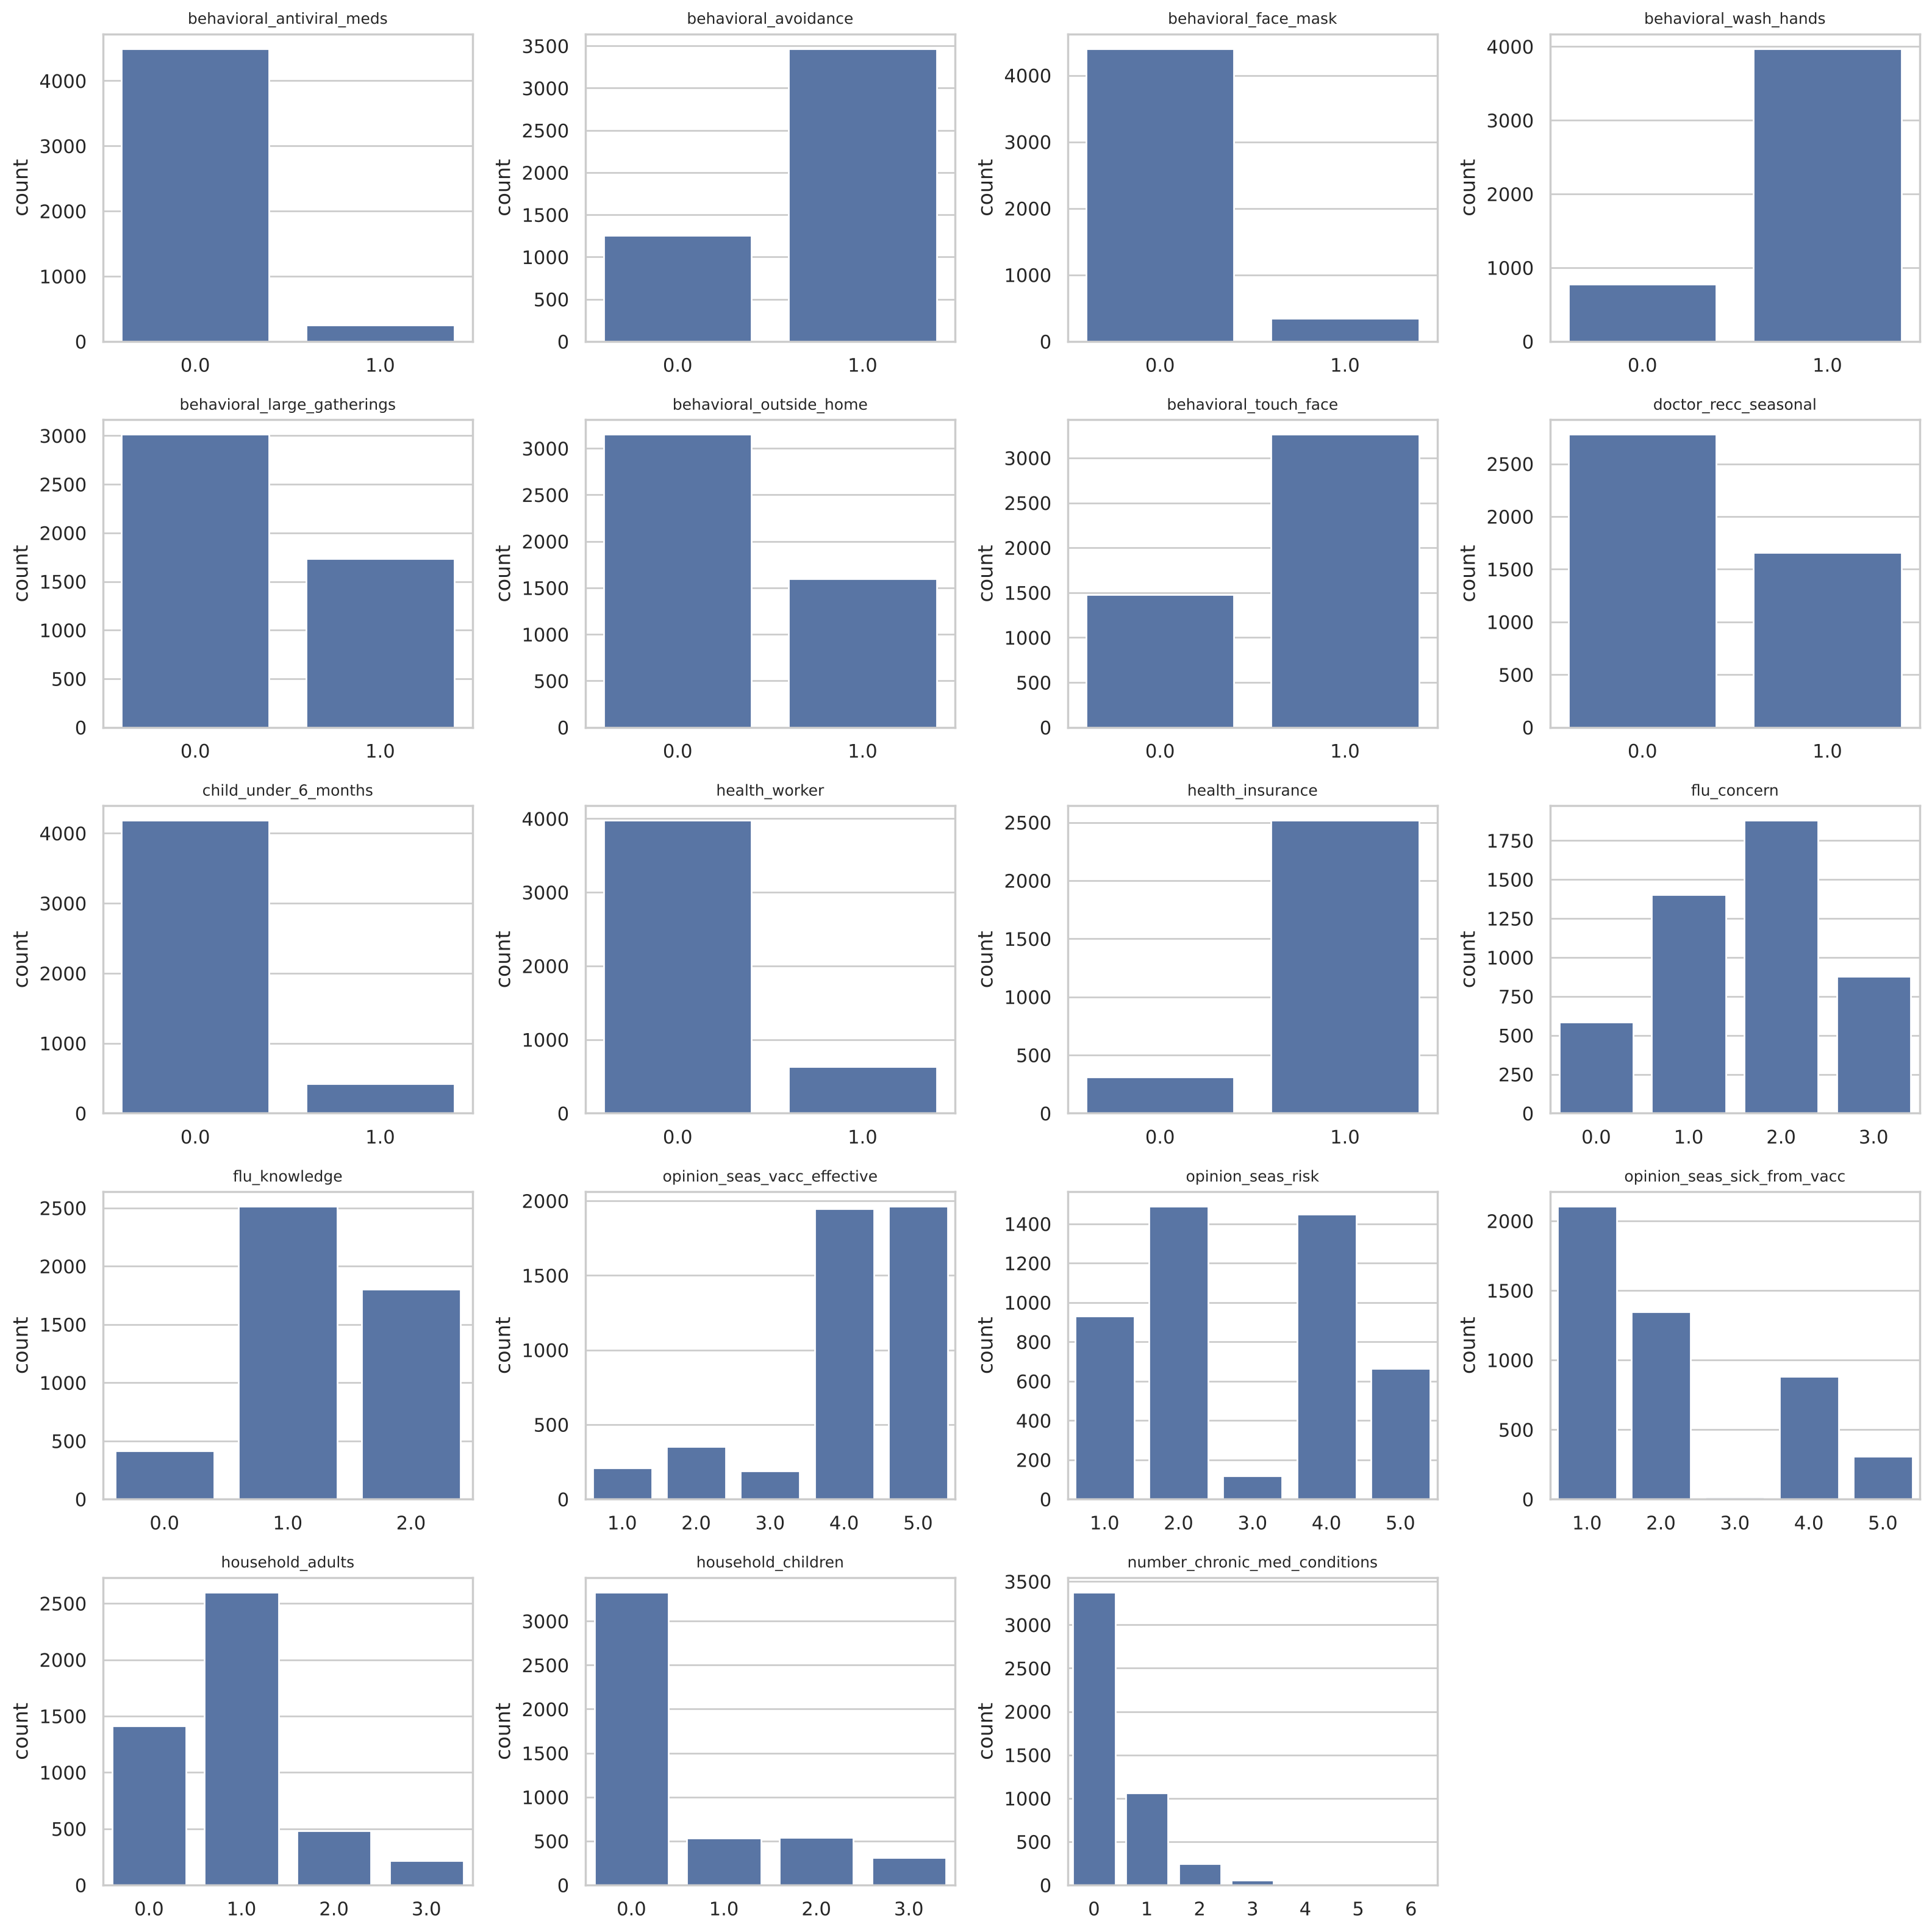

In [19]:
cols = BINARY + ORDINAL_NUM
fig, axes = plt.subplots(5, 4, figsize=(16, 16))
for ax, col in zip(axes.flat, cols):
    sns.countplot(x=train[col], ax=ax, color='#4c72b0')
    ax.set_title(col, fontsize=9); ax.set_xlabel('')
for ax in axes.flat[len(cols):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

### 3.5 Vaccination rate by feature
These plots show which features separate vaccinated from unvaccinated respondents.

In [20]:
def plot_rate(cols, ncols=4, order=None):
    """Bar plot of the vaccination rate for every level of each column."""
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows))
    for ax, col in zip(np.ravel(axes), cols):
        rate = train.groupby(train[col].fillna('Missing').astype(str))[TARGET].mean()
        if order and col in order:
            rate = rate.reindex([c for c in order[col] + ['Missing'] if c in rate.index])
        rate.plot.bar(ax=ax, color='#4c72b0')
        ax.axhline(train[TARGET].mean(), ls='--', c='grey')
        ax.set_title(col, fontsize=9); ax.set_xlabel(''); ax.set_ylim(0, 1)
        ax.tick_params(axis='x', labelsize=7, rotation=45)
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis('off')
    plt.tight_layout(); plt.show()

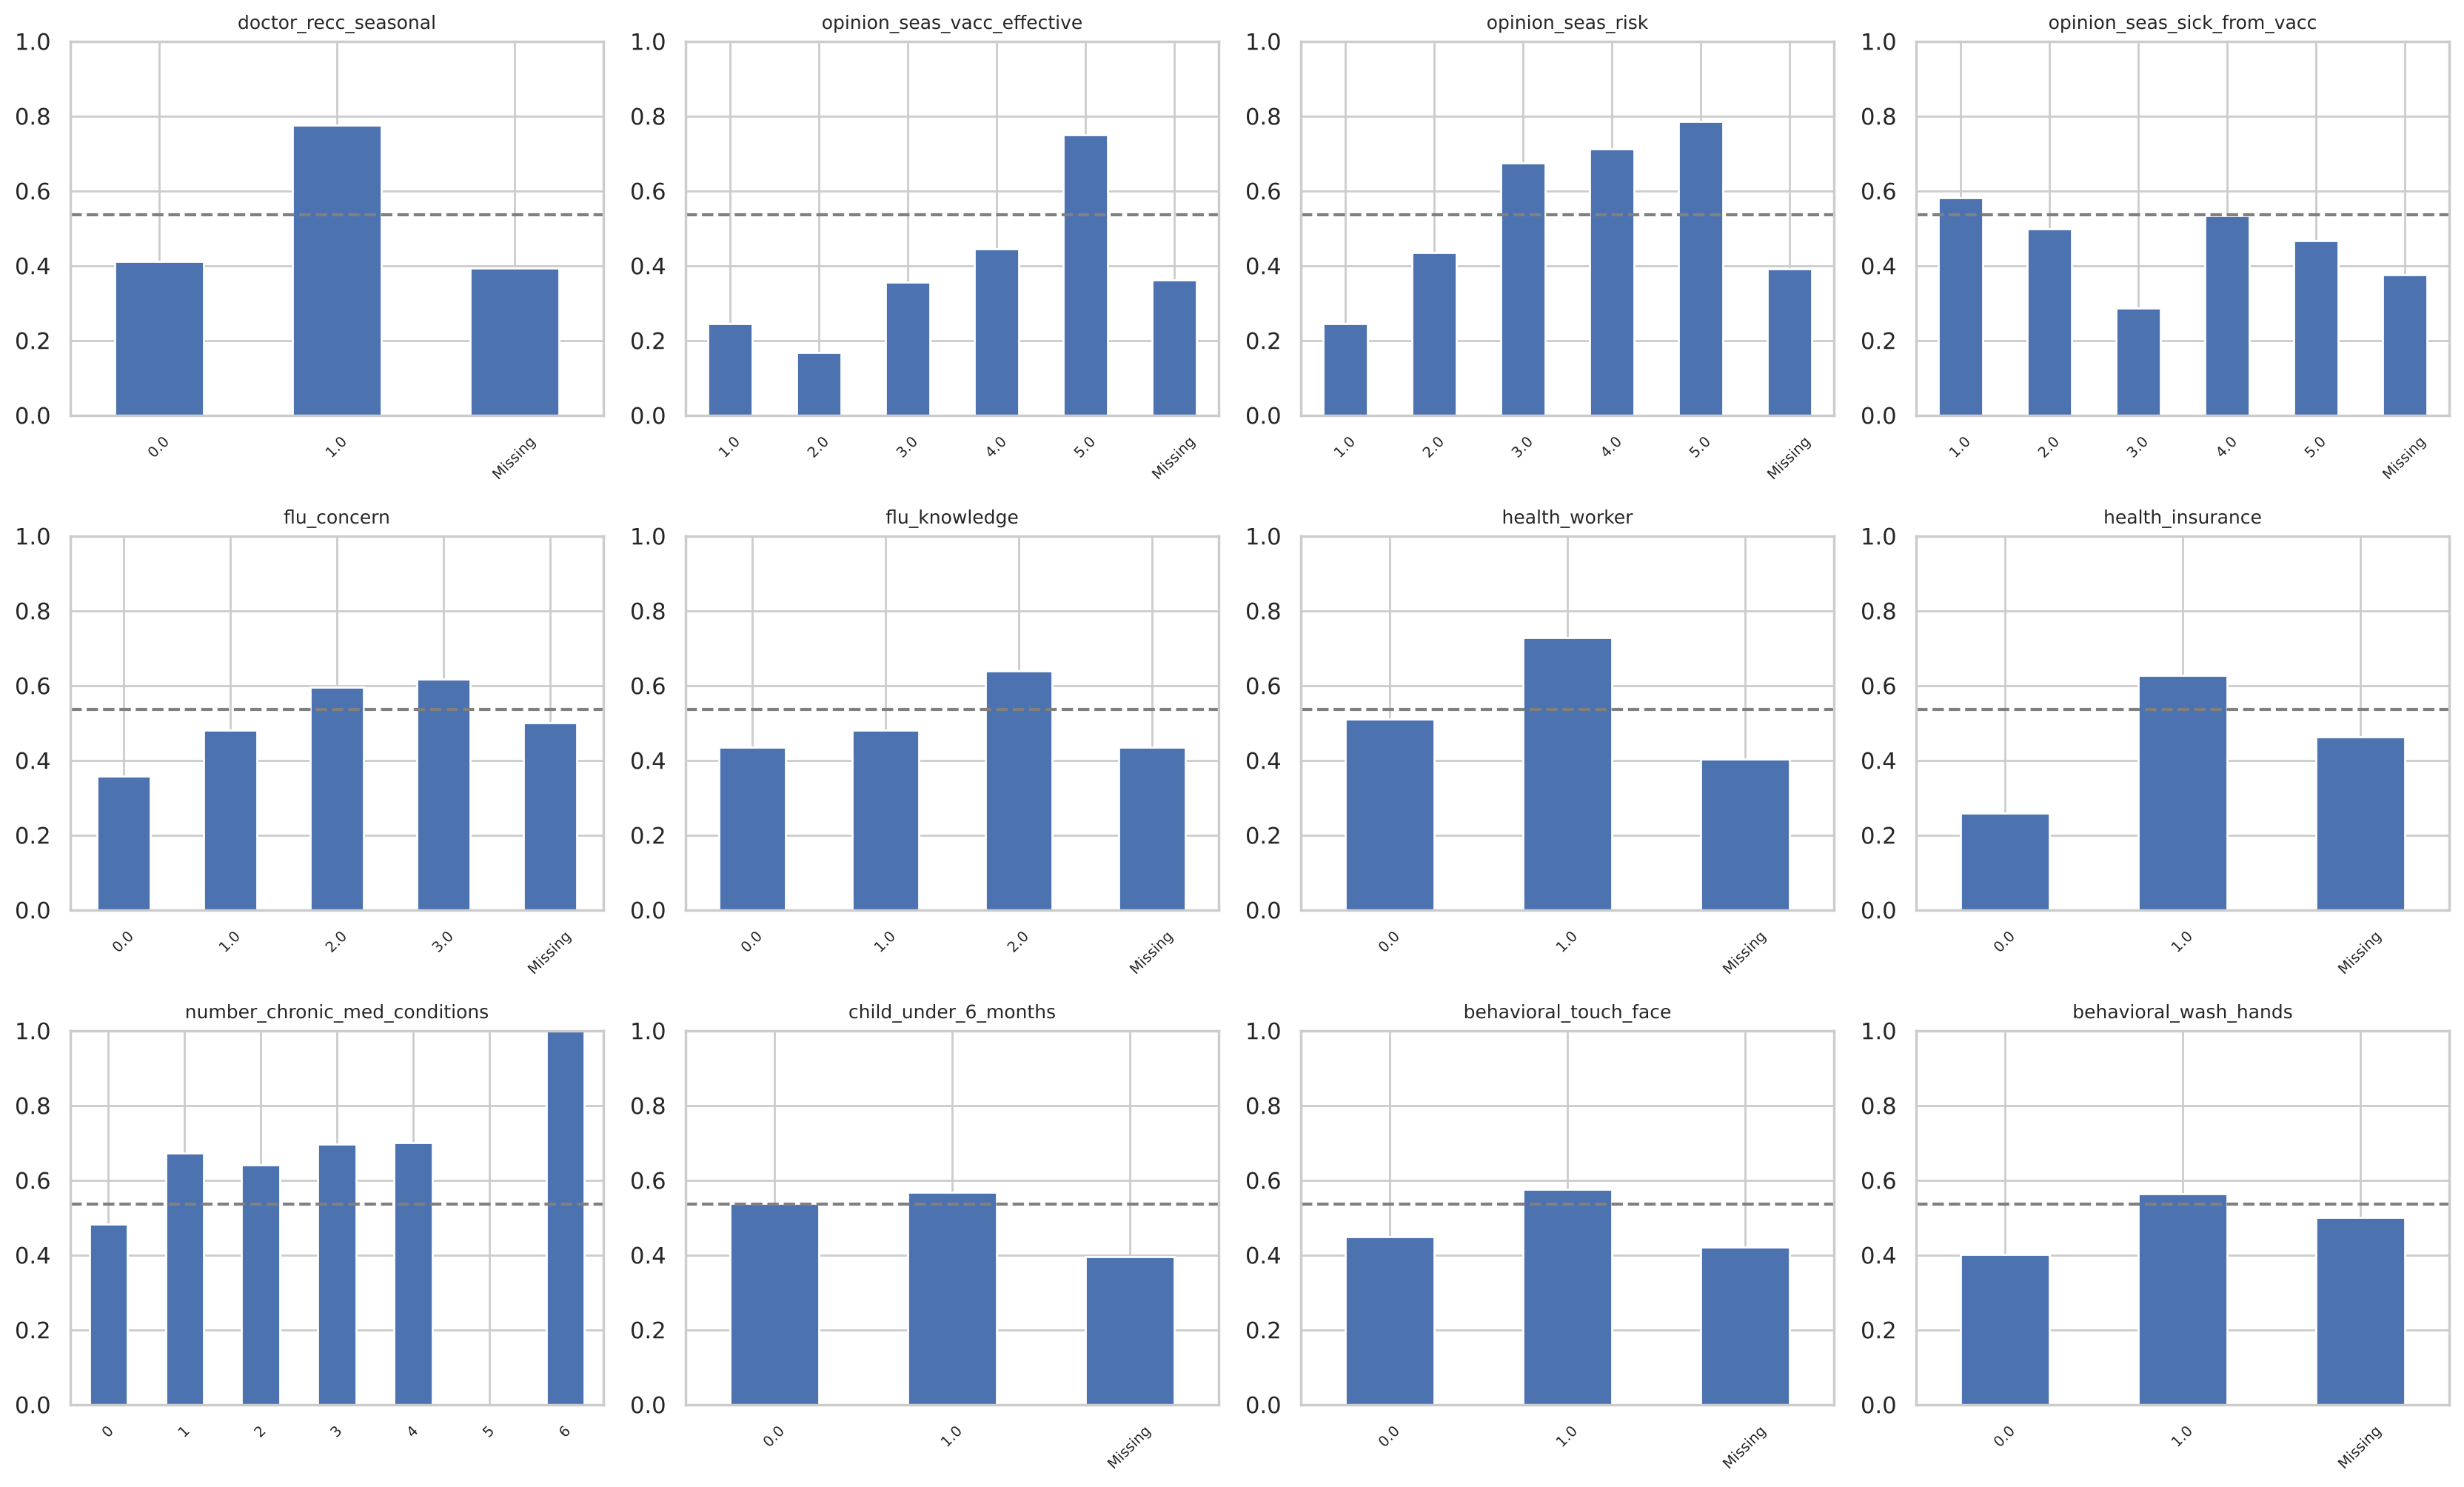

In [21]:
# Opinions, doctor recommendation and health-related features
plot_rate(['doctor_recc_seasonal', 'opinion_seas_vacc_effective', 'opinion_seas_risk',
           'opinion_seas_sick_from_vacc', 'flu_concern', 'flu_knowledge',
           'health_worker', 'health_insurance', 'number_chronic_med_conditions',
           'child_under_6_months', 'behavioral_touch_face', 'behavioral_wash_hands'])

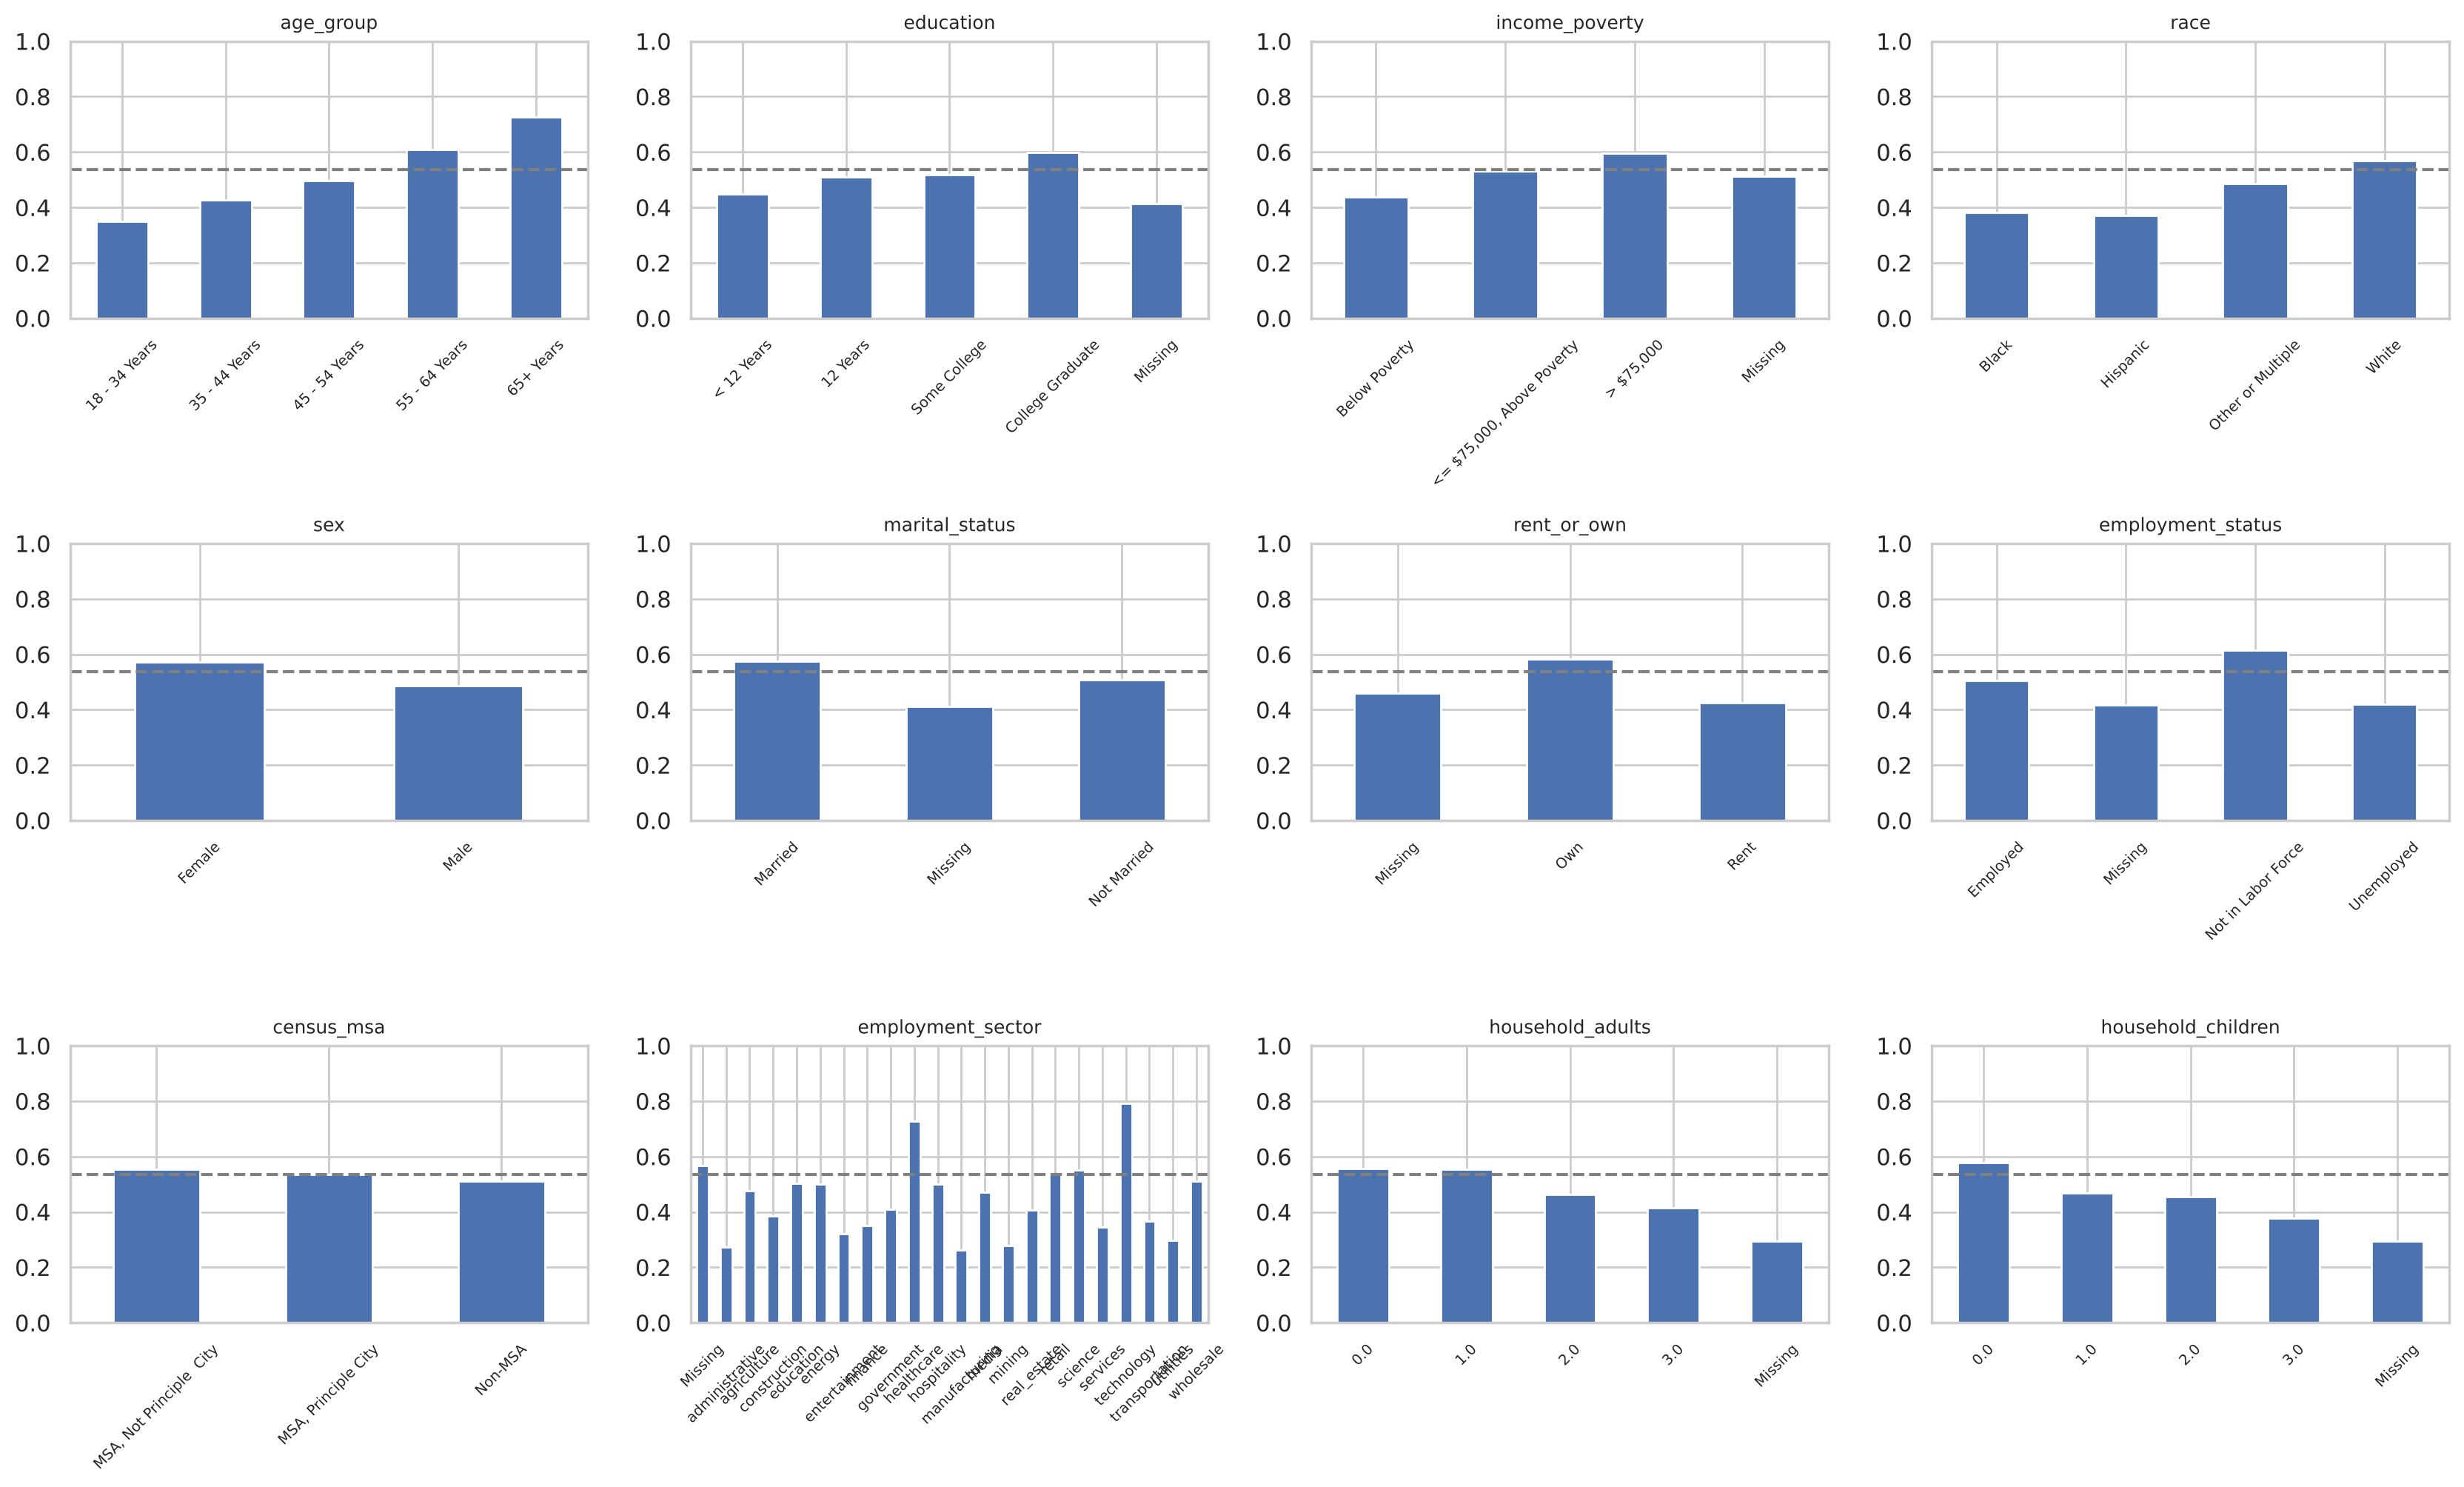

In [22]:
# Demographic features
plot_rate(list(ORDERED_CAT) + NOMINAL + ['household_adults', 'household_children'],
          order=ORDERED_CAT)

**Findings**
- **Doctor recommendation** is the strongest single signal: about 78% of those whose doctor recommended the vaccine took it, against about 41% of those whose doctor did not.
- **Age** has a clear monotonic effect (about 35% for 18–34 up to about 73% for 65+), which supports encoding it as an ordered rank.
- **Opinion on vaccine effectiveness** and **perceived risk** are strong. On these 1–5 scales, the "Don't know" level (3) does not
  always sit midway between its neighbours (e.g. risk = 3 has a higher rate than risk = 2). Treating the scales as numeric is a simplification that tree models can undo.
- Demographic features such as race, income and education have weaker but real effects.

### 3.6 Correlations between features

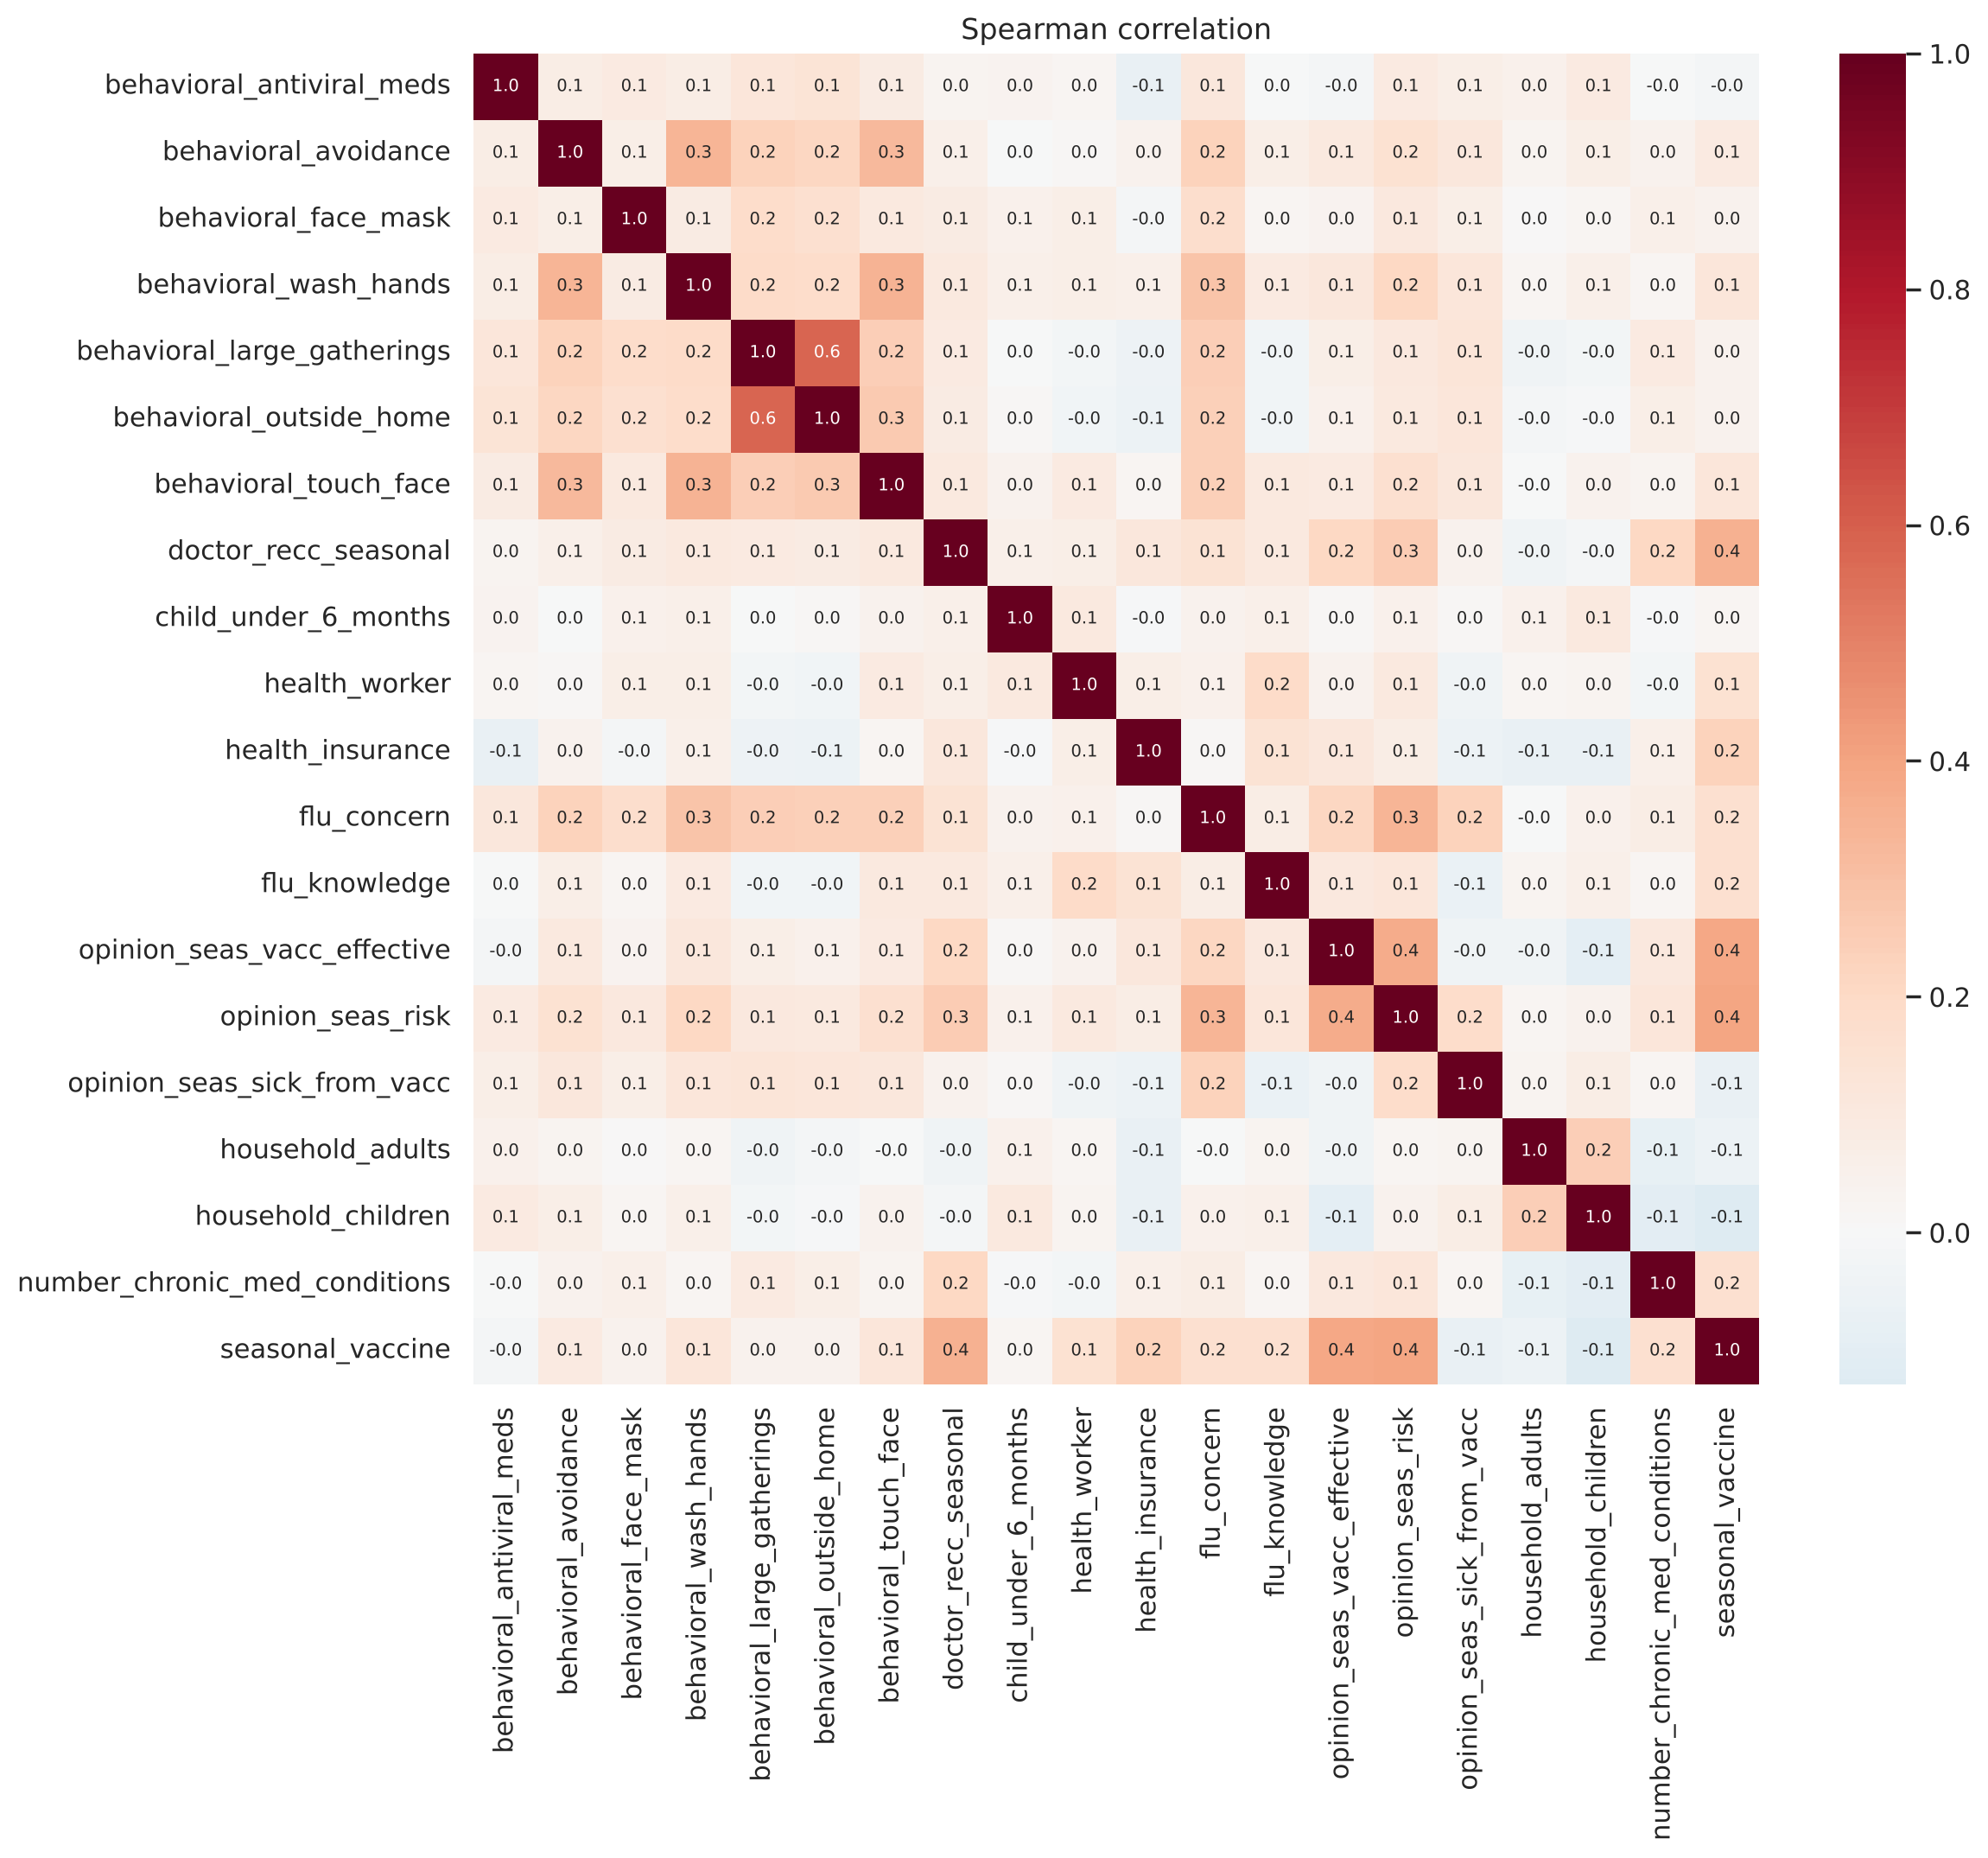

In [23]:
# Spearman correlation (suits ordinal scales)
corr = train[BINARY + ORDINAL_NUM + [TARGET]].corr(method='spearman')
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='RdBu_r', center=0, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Spearman correlation'); plt.show()

The behavioural features correlate with each other but none correlate very strongly (|r| < 0.6), so multicollinearity is not a serious problem. We keep all features; L2 regularisation in logistic regression handles the moderate overlap.

### 3.7 Feature relevance (mutual information)
Mutual information captures non-linear dependence with the target for every feature, including categoricals.

In [24]:
# Quick numeric encoding just for this analysis (missing -> -1)
mi_X = train[FEATURES].copy()
for col in list(ORDERED_CAT) + NOMINAL:
    mi_X[col] = mi_X[col].astype('category').cat.codes
mi_X = mi_X.fillna(-1)
mi = mutual_info_classif(mi_X, train[TARGET], discrete_features=True, random_state=RANDOM_STATE)
mi = pd.Series(mi, index=FEATURES).sort_values()

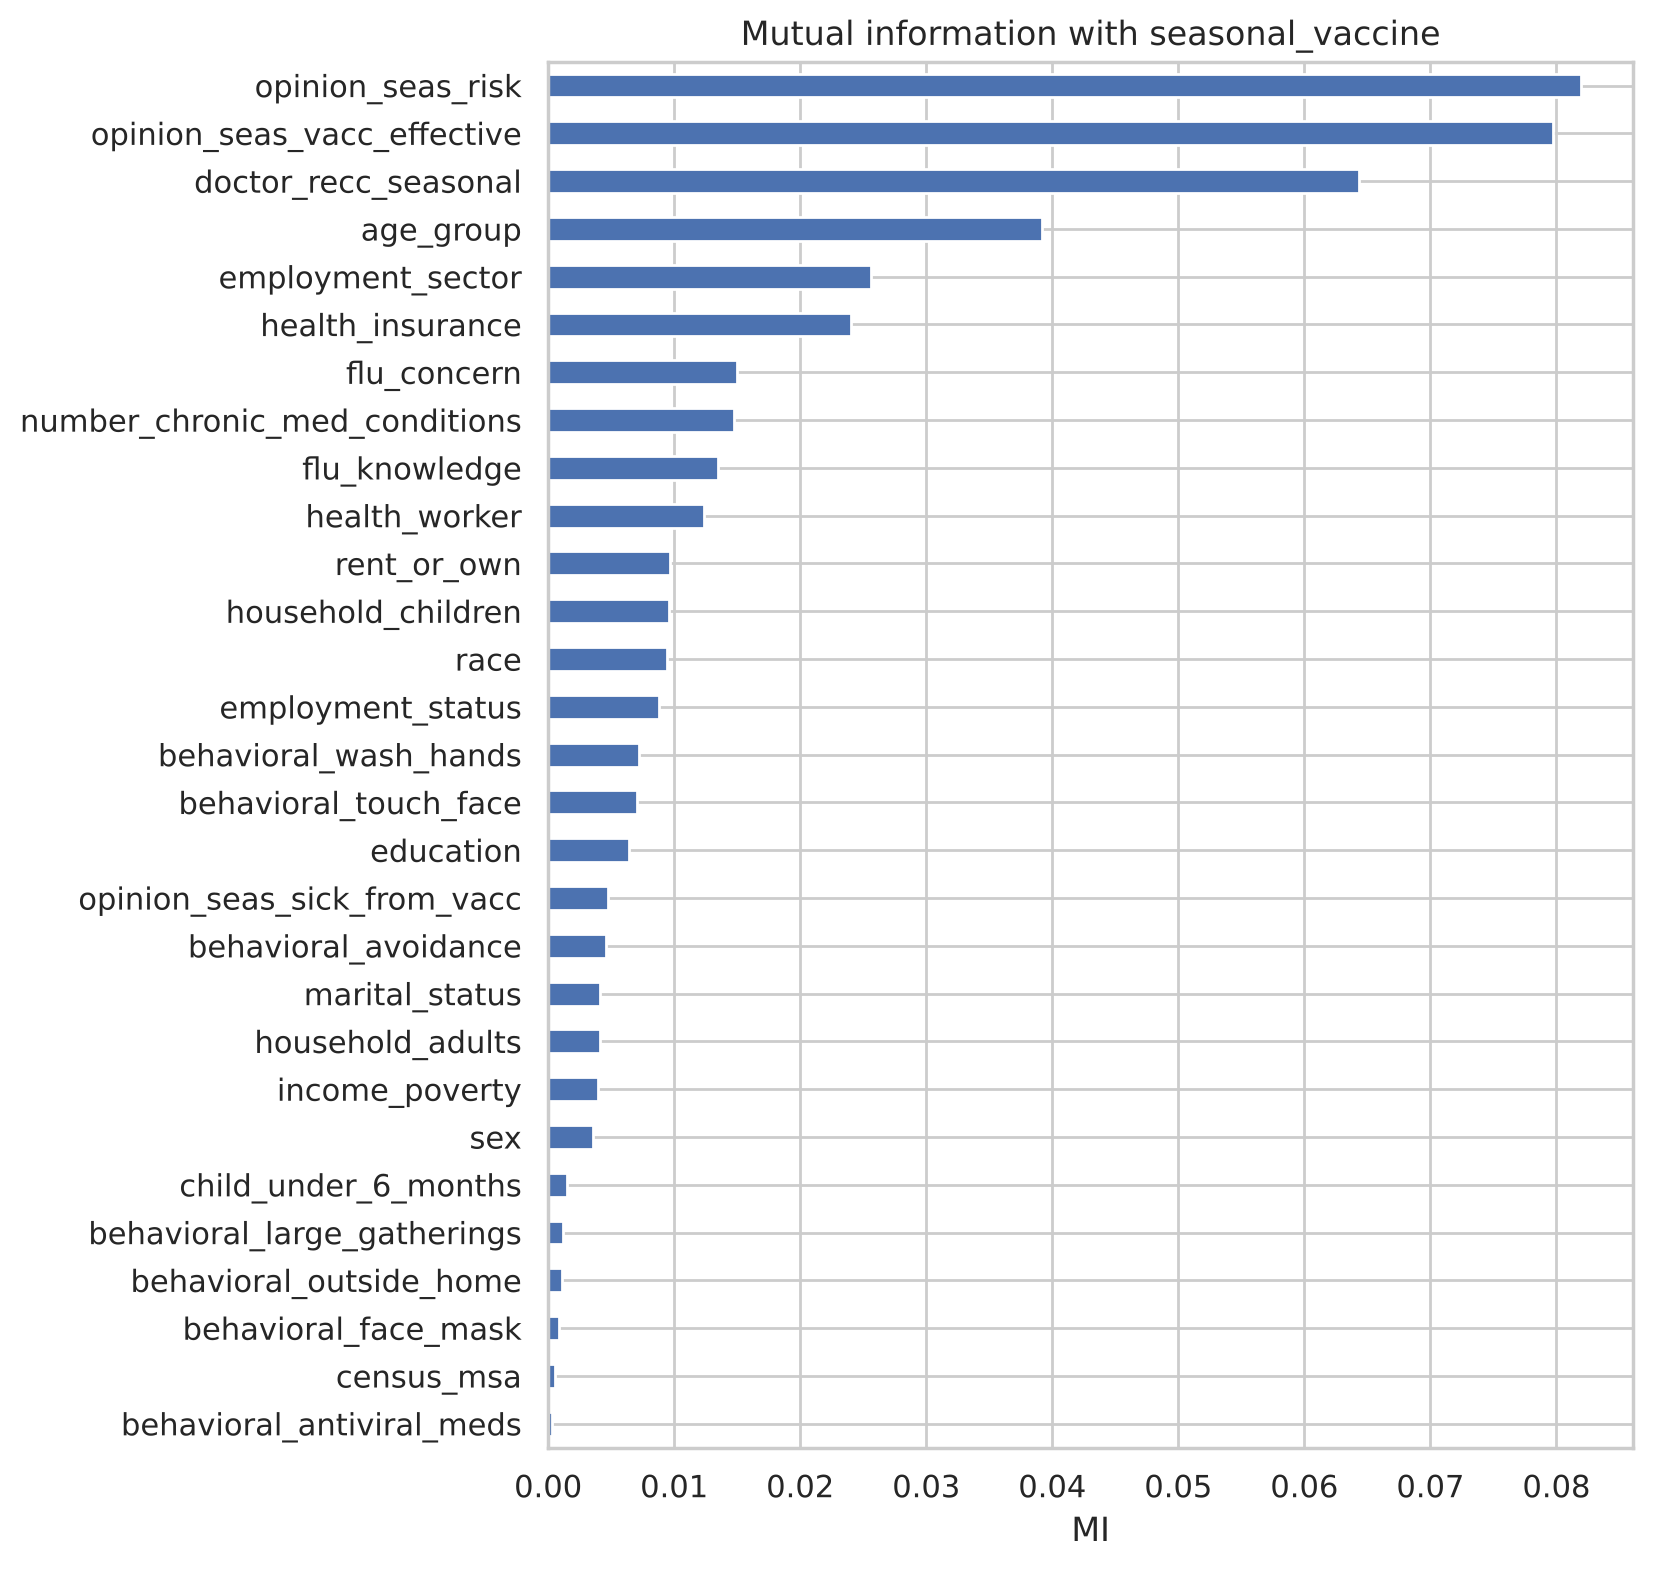

In [25]:
mi.plot.barh(figsize=(7, 9), color='#4c72b0')
plt.title('Mutual information with seasonal_vaccine'); plt.xlabel('MI')
plt.show()

### 3.8 Train vs test similarity
If the test set looks like the training set, cross-validation scores should carry over to the hidden test results.

In [26]:
shift = pd.DataFrame({'train_mean': train[BINARY + ORDINAL_NUM].mean(),
                      'test_mean': test[BINARY + ORDINAL_NUM].mean()})
shift['abs_diff'] = (shift.train_mean - shift.test_mean).abs()
shift.sort_values('abs_diff', ascending=False).round(3).head(8)

,train_mean,test_mean,abs_diff
flu_concern,1.643,1.691,0.048
opinion_seas_risk,2.877,2.917,0.040
household_adults,0.896,0.875,0.021
opinion_seas_vacc_effective,4.095,4.112,0.017
household_children,0.542,0.528,0.014
flu_knowledge,1.293,1.282,0.011
health_insurance,0.889,0.899,0.010
health_worker,0.137,0.130,0.007


The differences are tiny, so the test set comes from the same distribution as the training set.

## 4. Finding the evaluation metric
We are told to minimise a task-specific measure of prediction error, and we are given two costs:

| Item | Cost |
|---|---|
| Seasonal (H3N2) vaccine | \$300 |
| Hospitalisation for H3N2 flu | \$18,500 |

**How the predictions are used.** A public-health team uses the model to decide **who to contact and offer a vaccine**:
- If the model predicts **1 (already vaccinated)**, the person is **not** contacted.
- If the model predicts **0 (not vaccinated)**, the person is offered a vaccine.

**What each error costs**

| | Actually vaccinated (1) | Actually not vaccinated (0) |
|---|---|---|
| **Predict 1** | TP: correct, \$0 | **FP: person left unprotected → risk of hospitalisation, \$18,500** |
| **Predict 0** | **FN: unnecessary vaccine, \$300** | TN: correct, \$0 |

$$\text{Total cost} = 18{,}500 \times FP + 300 \times FN$$

A false positive is about **62× more expensive** than a false negative, so accuracy, F1 and other symmetric metrics are the wrong target.

In [27]:
# Cost matrix: change these values if the team adopts a different interpretation (see Section 11)
COSTS = {'TP': 0, 'TN': 0, 'FP': 18_500, 'FN': 300}

def total_cost(y_true, y_pred, costs=COSTS):
    """Total $ cost of a set of 0/1 predictions."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tp * costs['TP'] + tn * costs['TN'] + fp * costs['FP'] + fn * costs['FN']

In [28]:
def cost_per_person(y_true, y_pred, costs=COSTS):
    """Average cost per respondent, so data sets of different sizes can be compared."""
    return total_cost(y_true, y_pred, costs) / len(y_true)

**The cost-optimal decision threshold.** If a model gives probability $p$ that a person is vaccinated:
- predicting 1 has expected cost $(1-p) \times 18{,}500$
- predicting 0 has expected cost $p \times 300$

So we should predict 1 only when $p > \dfrac{C_{FP}-C_{TN}}{(C_{FP}-C_{TN}) + (C_{FN}-C_{TP})} = \dfrac{18{,}500}{18{,}800} \approx 0.984$.
The default 0.5 threshold would be very costly. This only works if the probabilities are **well calibrated**, so we tune models on log loss and check calibration (Section 8).

In [29]:
def bayes_threshold(costs=COSTS):
    """Probability above which predicting 1 has a lower expected cost than predicting 0."""
    a = costs['FP'] - costs['TN']
    b = costs['FN'] - costs['TP']
    return a / (a + b)

THRESHOLD = bayes_threshold()
print(f'Theoretical cost-optimal threshold: {THRESHOLD:.4f}')

Theoretical cost-optimal threshold: 0.9840


In [30]:
# Reference policies on the training data
y_all = train[TARGET]
for name, pred in {'Predict all 0 (offer everyone a vaccine)': np.zeros(len(y_all)),
                   'Predict all 1 (contact no one)': np.ones(len(y_all)),
                   'Predict truth (perfect model)': y_all}.items():
    print(f'{name:45s} ${cost_per_person(y_all, pred):8.2f} per person')

Predict all 0 (offer everyone a vaccine)      $  160.91 per person
Predict all 1 (contact no one)                $ 8577.06 per person
Predict truth (perfect model)                 $    0.00 per person


**Key insight.** Offering everyone a vaccine costs \$300 for each person who is already vaccinated (about \$161 per person), whereas wrongly
skipping an unvaccinated person costs \$18,500. Our model must beat the **"predict all 0" baseline**. To do that, it has to find people it is
almost certain (above 98.4%) are already vaccinated. Accuracy-oriented models will not do this, which is why the metric drives every later choice.

## 5. Decisions passed on to the model notebooks
- **Metric:** total cost = \$18,500 × FP + \$300 × FN, reported per person. The cost-optimal threshold is **0.984**.
- **Baseline to beat:** "predict all 0" (offer everyone a vaccine).
- **Pre-processing:** every model notebook compares Option A (simple) with Option B (missing-aware) for its own model. Option B is motivated by this EDA:
  `employment_sector` is structurally missing, and missing `health_insurance` is informative.
- **Validation:** the same 80/20 hold-out split and the same CV folds (`RANDOM_STATE = 42`) in every notebook, so the five models' results are directly comparable.